In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:

customers = pd.read_csv('Ecommerce Customers')
customers.head()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
0,mstephenson@fernandez.com,"835 Frank Tunnel\r\nWrightmouth, MI 82180-9605",Violet,34.497268,12.655651,39.577668,4.082621,587.951054
1,hduke@hotmail.com,"4547 Archer Common\r\nDiazchester, CA 06566-8576",DarkGreen,31.926272,11.109461,37.268959,2.664034,392.204933
2,pallen@yahoo.com,"24645 Valerie Unions Suite 582\r\nCobbborough,...",Bisque,33.000915,11.330278,37.110597,4.104543,487.547505
3,riverarebecca@gmail.com,"1414 David Throughway\r\nPort Jason, OH 22070-...",SaddleBrown,34.305557,13.717514,36.721283,3.120179,581.852344
4,mstephens@davidson-herman.com,"14023 Rodriguez Passage\r\nPort Jacobville, PR...",MediumAquaMarine,33.330673,12.795189,37.536653,4.446308,599.406092


In [3]:
customers.tail()

,Email,Address,Avatar,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
495,lewisjessica@craig-evans.com,4483 Jones Motorway Suite 872\r\nLake Jamiefur...,Tan,33.237660,13.566160,36.417985,3.746573,573.847438
496,katrina56@gmail.com,"172 Owen Divide Suite 497\r\nWest Richard, CA ...",PaleVioletRed,34.702529,11.695736,37.190268,3.576526,529.049004
497,dale88@hotmail.com,0787 Andrews Ranch Apt. 633\r\nSouth Chadburgh...,Cornsilk,32.646777,11.499409,38.332576,4.958264,551.620145
498,cwilson@hotmail.com,"680 Jennifer Lodge Apt. 808\r\nBrendachester, ...",Teal,33.322501,12.391423,36.840086,2.336485,456.469510
499,hannahwilson@davidson.com,49791 Rachel Heights Apt. 898\r\nEast Drewboro...,DarkMagenta,33.715981,12.418808,35.771016,2.735160,497.778642


In [4]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Email                 500 non-null    object 
 1   Address               500 non-null    object 
 2   Avatar                500 non-null    object 
 3   Avg. Session Length   500 non-null    float64
 4   Time on App           500 non-null    float64
 5   Time on Website       500 non-null    float64
 6   Length of Membership  500 non-null    float64
 7   Yearly Amount Spent   500 non-null    float64
dtypes: float64(5), object(3)
memory usage: 31.4+ KB


In [5]:
customers.shape

(500, 8)

In [6]:
customers.dtypes

Email                    object
Address                  object
Avatar                   object
Avg. Session Length     float64
Time on App             float64
Time on Website         float64
Length of Membership    float64
Yearly Amount Spent     float64
dtype: object

In [9]:
customers.describe()

,Avg. Session Length,Time on App,Time on Website,Length of Membership,Yearly Amount Spent
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,33.053194,12.052488,37.060445,3.533462,499.314038
std,0.992563,0.994216,1.010489,0.999278,79.314782
min,29.532429,8.508152,33.913847,0.269901,256.670582
25%,32.341822,11.388153,36.349257,2.930450,445.038277
50%,33.082008,11.983231,37.069367,3.533975,498.887875
75%,33.711985,12.753850,37.716432,4.126502,549.313828
max,36.139662,15.126994,40.005182,6.922689,765.518462


<Axes: >

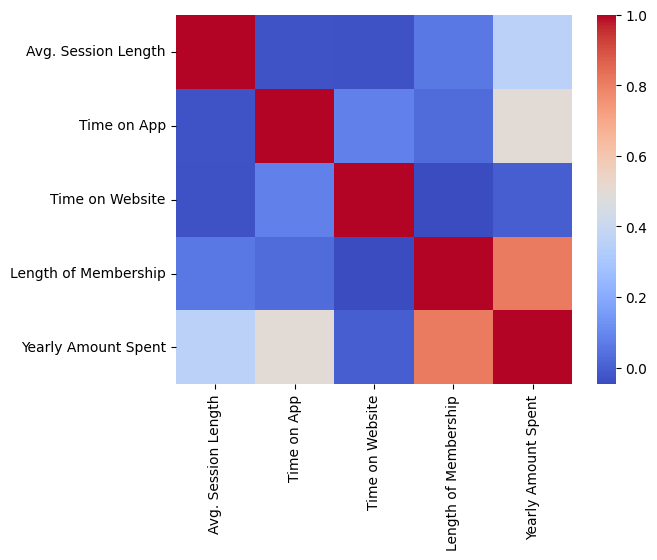

In [31]:
sns.heatmap(customers.corr(numeric_only=True), cmap = 'coolwarm')

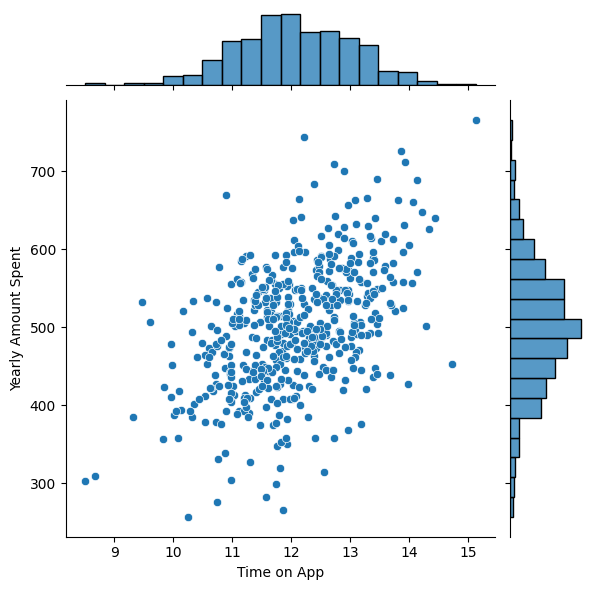

In [26]:
sns.jointplot(customers, x='Time on App', y='Yearly Amount Spent')


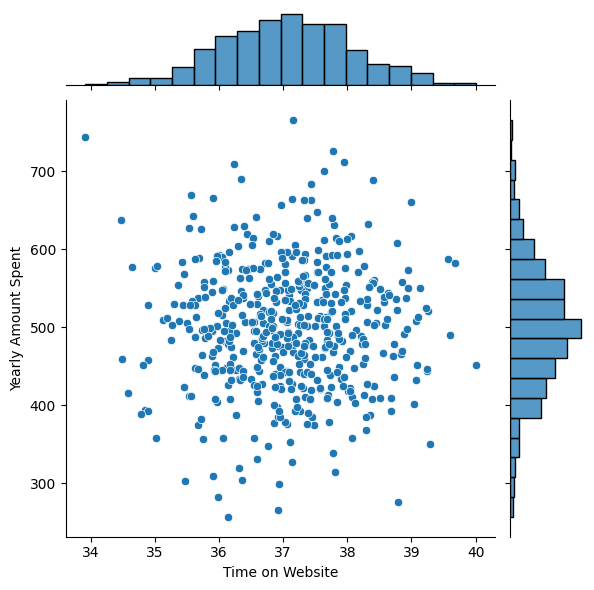

In [27]:
sns.jointplot(customers, x = 'Time on Website', y = 'Yearly Amount Spent')

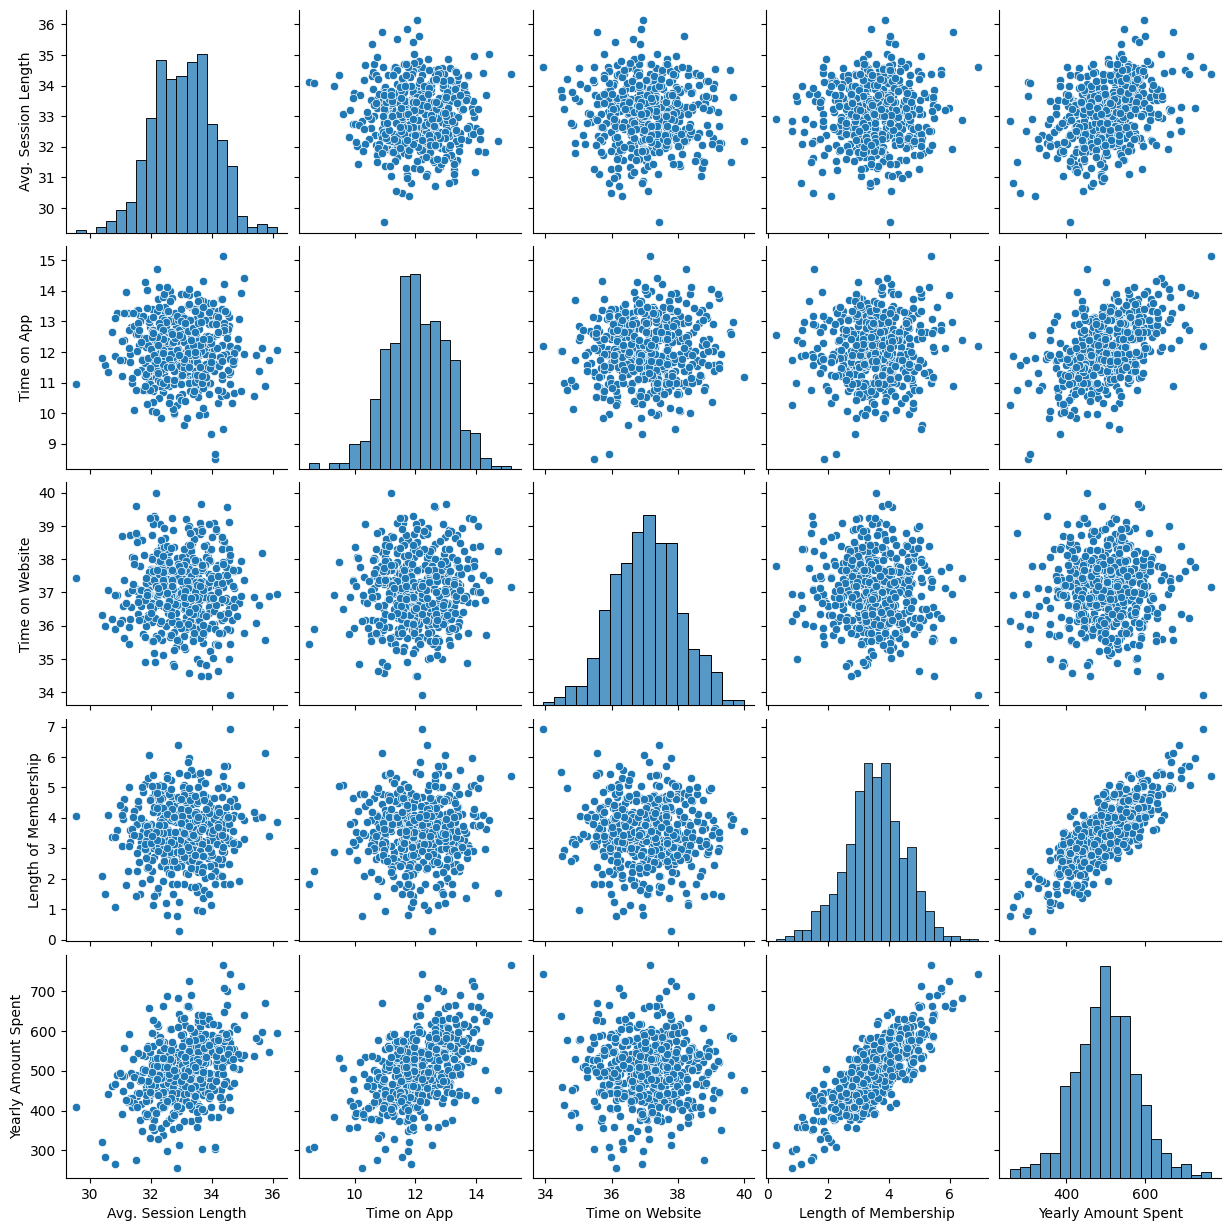

In [13]:
sns.pairplot(customers)
plt.show()

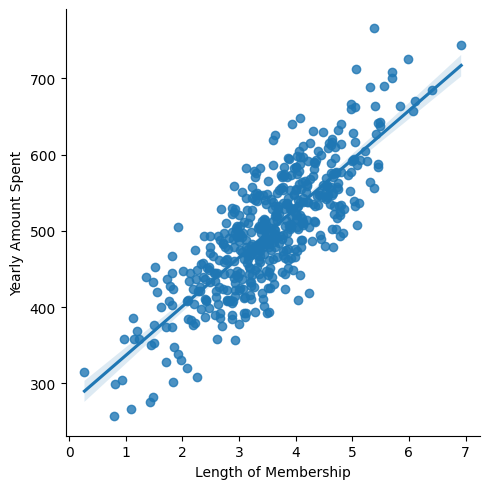

In [14]:
sns.lmplot(x="Length of Membership", y="Yearly Amount Spent", data=customers)

In [15]:
x = customers[['Avg. Session Length', 'Time on App','Time on Website', 'Length of Membership']]
y = customers['Yearly Amount Spent']
x.shape, y.shape

((500, 4), (500,))

In [16]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y, test_size=0.3, random_state=101)


In [17]:
from sklearn.linear_model import LinearRegression
lm = LinearRegression()
lm.fit(X_train, y_train)

LinearRegression()

In [18]:
print(lm.coef_)

[25.98154972 38.59015875  0.19040528 61.27909654]


In [19]:
predictions = lm.predict(X_test)

In [20]:
print(predictions[0:5])

[456.44186104 402.72005312 409.2531539  591.4310343  590.01437275]


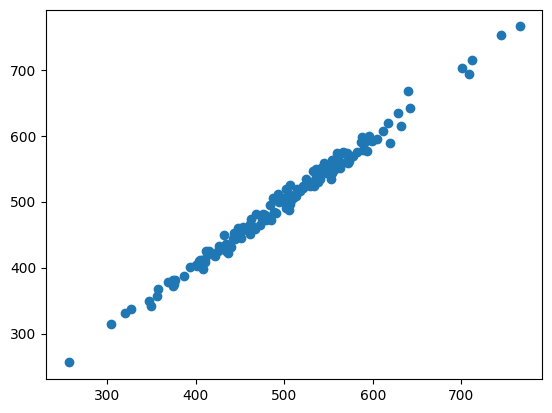

In [21]:
plt.scatter(y_test, predictions)

In [22]:
from sklearn import metrics
print('MAE: {}'.format(metrics.mean_absolute_error(y_test, predictions)))
print('MSE: {}'.format(metrics.mean_squared_error(y_test, predictions)))
print('RMSE: {}'.format(np.sqrt(metrics.mean_squared_error(y_test, predictions))))

print('Rsquared: {}'.format(metrics.explained_variance_score(y_test, predictions)))

MAE: 7.228148653430826
MSE: 79.81305165097427
RMSE: 8.933815066978624
Rsquared: 0.9890771231889606


C:\Users\ABDALAH\AppData\Local\Temp\ipykernel_11636\2747667862.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test-predictions), bins = 50)


<Axes: xlabel='Yearly Amount Spent', ylabel='Density'>

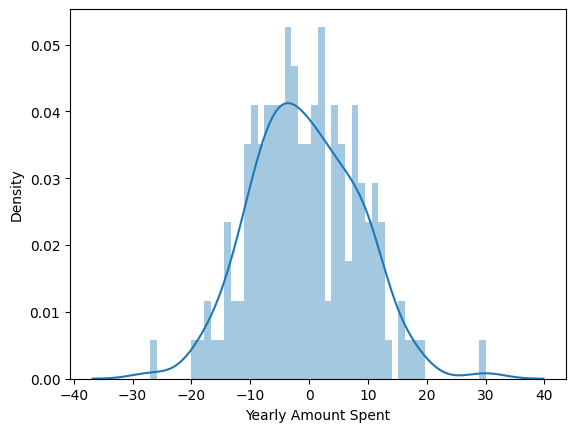

In [28]:
sns.distplot((y_test-predictions), bins = 50)

In [25]:
coef = pd.DataFrame(lm.coef_, x.columns, columns = ['Coefficient'])
coef

,Coefficient
Avg. Session Length,25.981550
Time on App,38.590159
Time on Website,0.190405
Length of Membership,61.279097


USA Housing

In [29]:
USAhousing = pd.read_csv('USA_Housing.csv')
USAhousing.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\r\nLaurabury, NE 37..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\r\nLake Kathleen, ..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\r\nDanieltown, WI 064..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\r\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\r\nFPO AE 09386


In [32]:
USAhousing.shape

(5000, 7)

In [33]:
USAhousing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [36]:
USAhousing.isna().sum()

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [37]:
USAhousing[['Address']]

,Address
0,"208 Michael Ferry Apt. 674\r\nLaurabury, NE 37..."
1,"188 Johnson Views Suite 079\r\nLake Kathleen, ..."
2,"9127 Elizabeth Stravenue\r\nDanieltown, WI 064..."
3,USS Barnett\r\nFPO AP 44820
4,USNS Raymond\r\nFPO AE 09386
...,...
4995,USNS Williams\r\nFPO AP 30153-7653
4996,"PSC 9258, Box 8489\r\nAPO AA 42991-3352"
4997,"4215 Tracy Garden Suite 076\r\nJoshualand, VA ..."
4998,USS Wallace\r\nFPO AE 73316


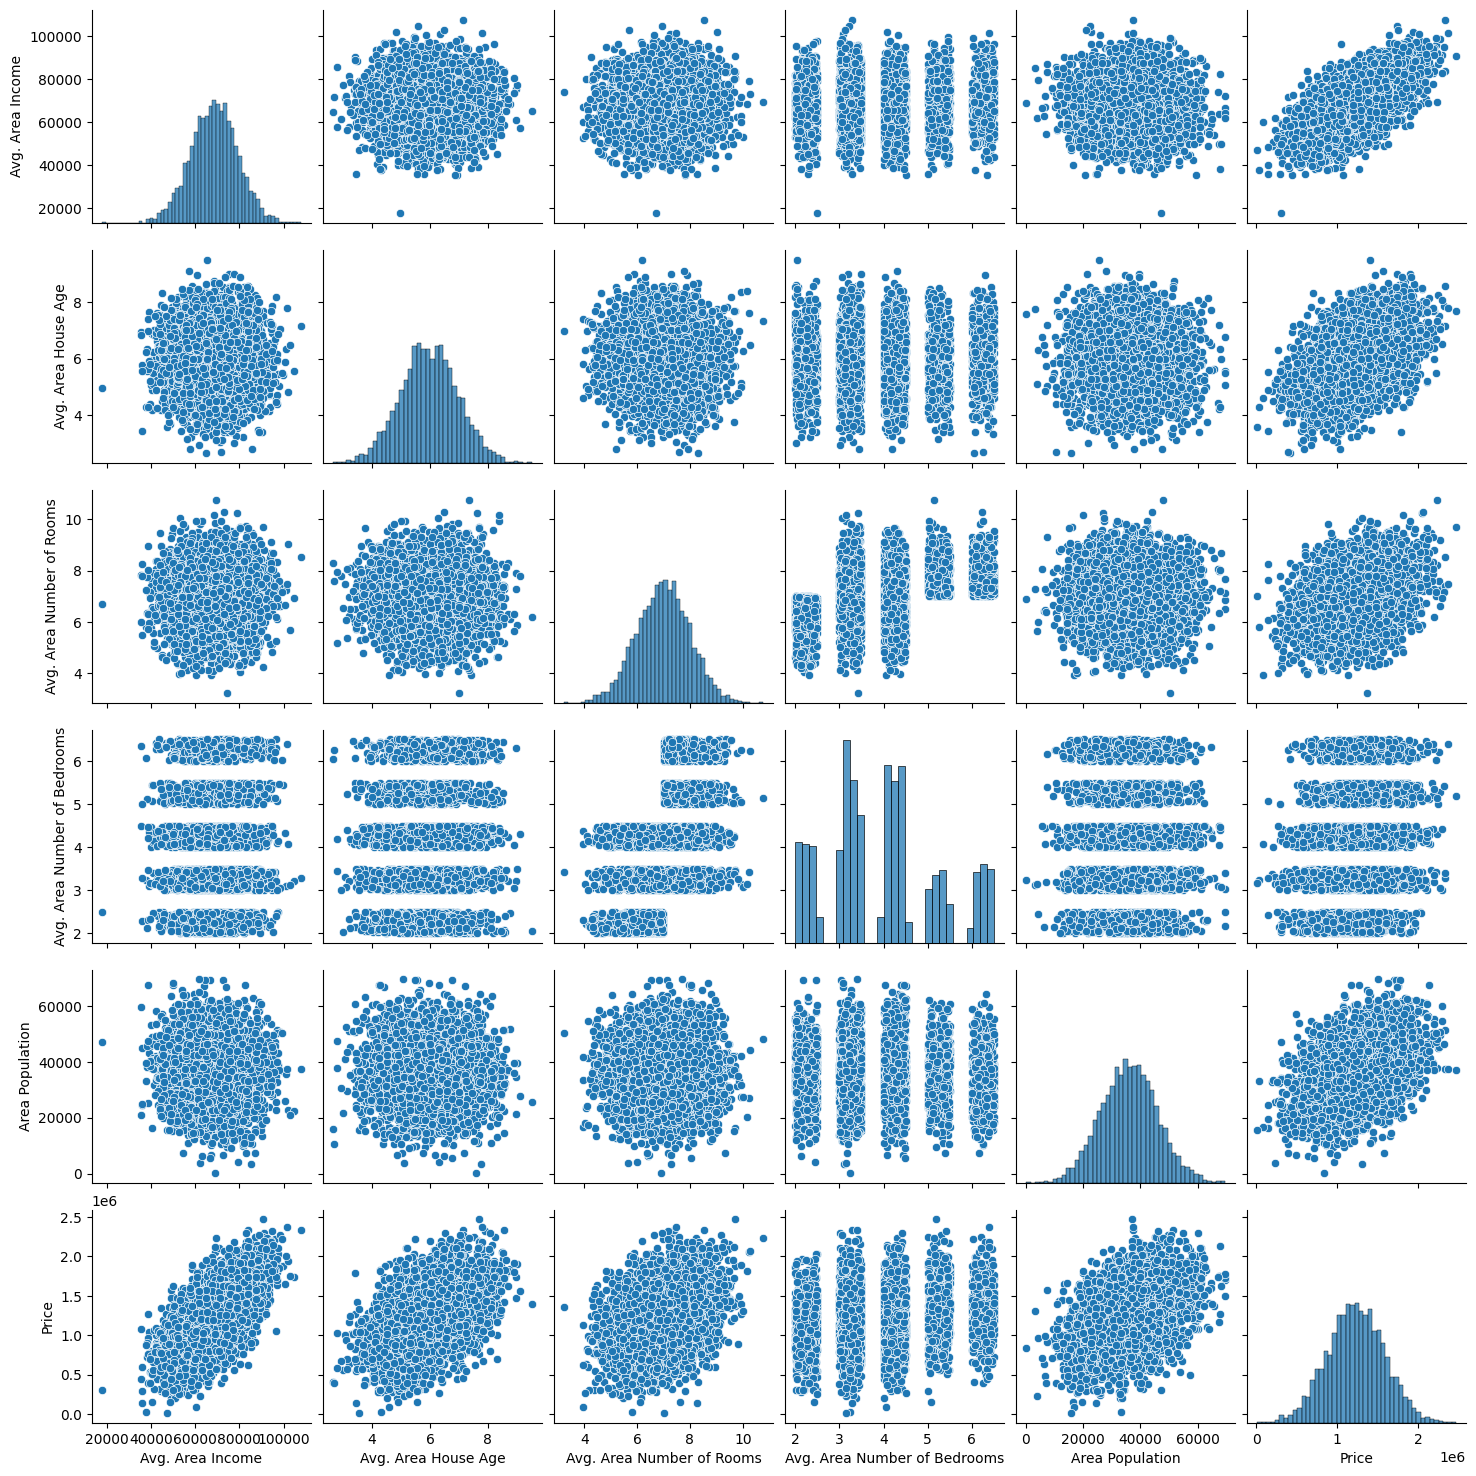

In [38]:
sns.pairplot(USAhousing)

<Axes: >

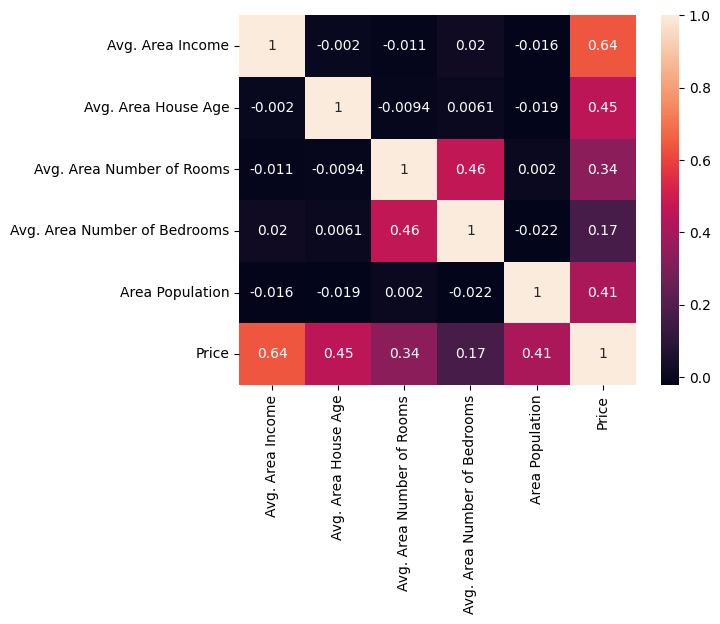

In [39]:
sns.heatmap(USAhousing.corr(numeric_only=True), annot = True)

In [45]:
USAhousing[["Address"]].value_counts().count()

np.int64(5000)

so, there are like 5000 different addresses in here, which means that data were taken at different places which is valid from point of view to analyse every location

In [46]:
USAhousing.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


In [47]:
USAhousing.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

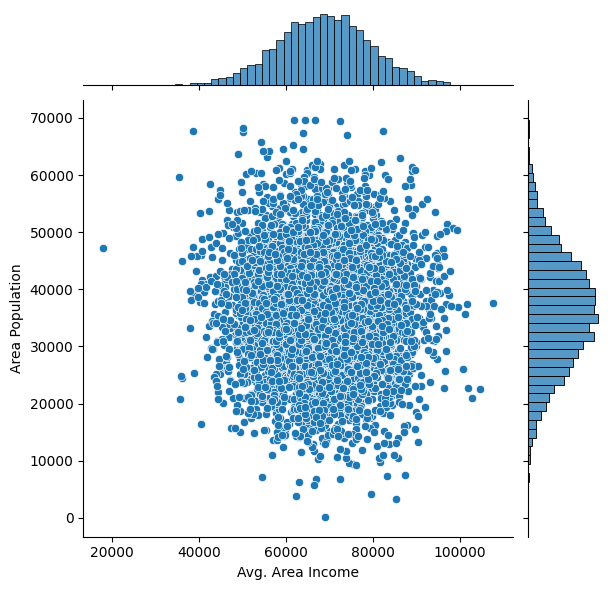

In [48]:
sns.jointplot(USAhousing, x = "Avg. Area Income", y = 'Area Population')

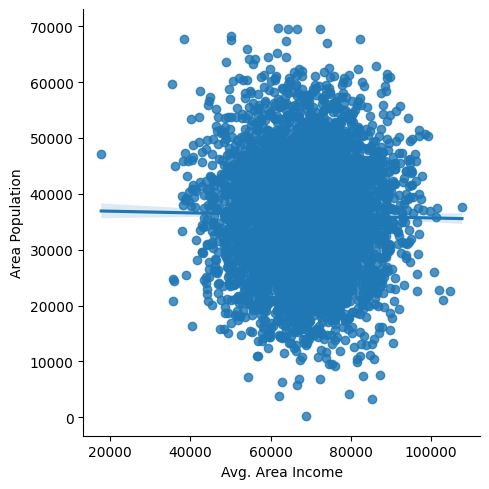

In [49]:
sns.lmplot(USAhousing, x = "Avg. Area Income", y = 'Area Population')

As population increases, the average area income decreases(negatively correlated)

<Axes: xlabel='Avg. Area Income', ylabel='Count'>

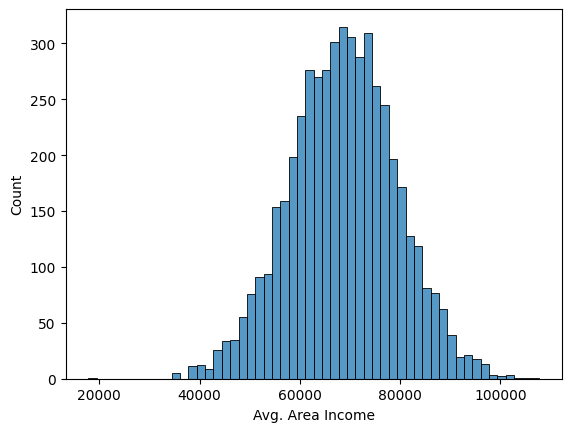

In [50]:
sns.histplot(USAhousing, x= 'Avg. Area Income')

In [54]:
x_housing = USAhousing[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population']]
y_housing = USAhousing[['Price']]
X_train_h, X_test_h, y_train_h, y_test_h = train_test_split(x_housing, y_housing, test_size = 0.3, random_state = 101)
X_train_h.shape, y_train_h.shape

((3500, 5), (3500, 1))

In [55]:
lm.fit(X_train_h,y_train_h)

LinearRegression()

In [56]:
lm.coef_

array([[2.16176350e+01, 1.65221120e+05, 1.21405377e+05, 1.31871878e+03,
        1.52251955e+01]])

In [58]:
data_results = pd.DataFrame(lm.coef_[0], x_housing.columns,columns= ['Coefficients'])

In [59]:
data_results

,Coefficients
Avg. Area Income,21.617635
Avg. Area House Age,165221.119872
Avg. Area Number of Rooms,121405.376596
Avg. Area Number of Bedrooms,1318.718783
Area Population,15.225196


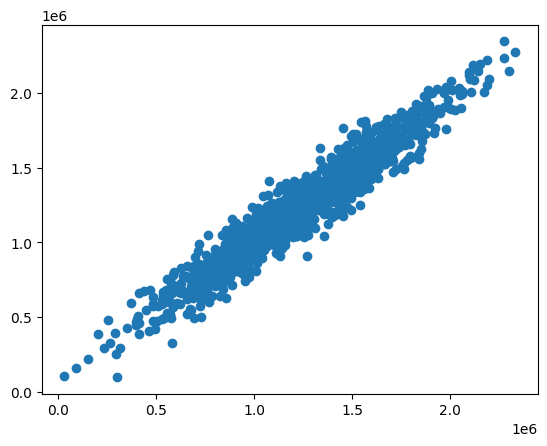

In [60]:
predictions_housing = lm.predict(X_test_h)
plt.scatter(y_test_h, predictions_housing)

C:\Users\ABDALAH\AppData\Local\Temp\ipykernel_11636\1637431007.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot((y_test_h - predictions_housing))


<Axes: ylabel='Density'>

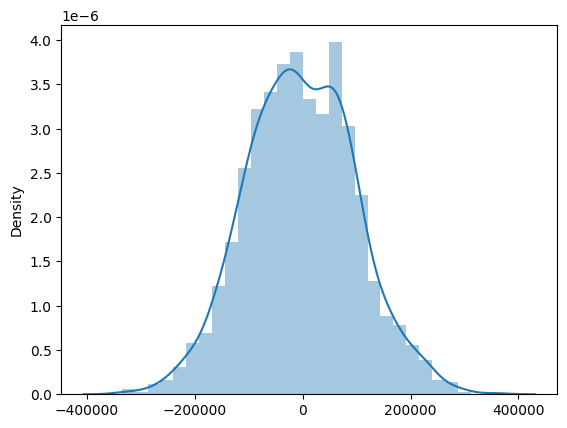

In [61]:
sns.distplot((y_test_h - predictions_housing))

In [63]:
print(f'MAE: {metrics.mean_absolute_error(y_test_h, predictions_housing)}')
print(f'MSE: {metrics.mean_squared_error(y_test_h, predictions_housing)}')
print(f'RMSE: {np.sqrt(metrics.mean_squared_error(y_test_h, predictions_housing))}')

print('Rsquared: {}'.format(metrics.explained_variance_score(y_test_h, predictions_housing)))

MAE: 81257.55795855941
MSE: 10169125565.897606
RMSE: 100842.08231635048
Rsquared: 0.918582277096528


In [64]:
print(lm.intercept_)

[-2641372.66730143]


C:\Users\ABDALAH\AppData\Local\Temp\ipykernel_11636\812483608.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(USAhousing['Price'])


<Axes: xlabel='Price', ylabel='Density'>

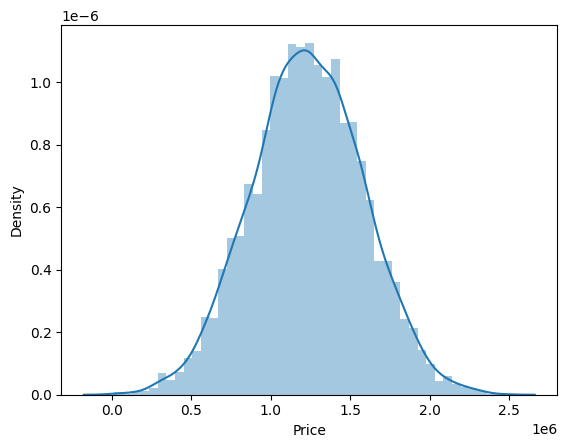

In [65]:
sns.distplot(USAhousing['Price'])